In [1]:
import pandas as pd
import numpy as np
import os

print(pd.__version__)
print(np.__version__)
print("All libraries are loaded! ")

3.0.5
2.4.6
All libraries are loaded! 


In [2]:
#Listing all .csv files in this folder
files = [f for f in os.listdir('.') if f.endswith('.csv')]
files.sort()
for f in files:
    print(f)

2018.csv
2019.csv
2020.csv
2021.csv
2022.csv
2023.csv
2024.csv
2025.csv
income_expenditure2018.csv
income_expenditure2019.csv
income_expenditure2020.csv
income_expenditure2021.csv
income_expenditure2022.csv
income_expenditure2023.csv
income_expenditure2024.csv
income_expenditure2025.csv
model_results.csv
municipal_data_clean.csv
repairs_maintenance2019.csv
repairs_maintenance2020.csv
repairs_maintenance2021.csv
repairs_maintenance2022.csv
repairs_maintenance2023.csv
repairs_maintenance2024.csv
repairs_maintenance2025.csv
unauthorised_irregular_fruitless_wasteful_expenditure2012.csv
unauthorised_irregular_fruitless_wasteful_expenditure2013.csv
unauthorised_irregular_fruitless_wasteful_expenditure2014.csv
unauthorised_irregular_fruitless_wasteful_expenditure2015.csv
unauthorised_irregular_fruitless_wasteful_expenditure2016.csv
unauthorised_irregular_fruitless_wasteful_expenditure2017.csv
unauthorised_irregular_fruitless_wasteful_expenditure2018.csv
unauthorised_irregular_fruitless_wastef

In [3]:
#Inspecting each file from the dataset
print("2018.csv (capital acquisition)")
df_test = pd.read_csv('2018.csv')
print(df_test.columns.tolist())
print(df_test.head(3))

print("\nincome_expenditure2018.csv")
df_test2 = pd.read_csv('income_expenditure2018.csv')
print(df_test2.columns.tolist())
print(df_test2.head(3))

print("\nrepairs_maintenance2019.csv")
df_test3 = pd.read_csv('repairs_maintenance2019.csv')
print(df_test3.columns.tolist())
print(df_test3.head(3))

print("\nunauthorised_irregular_fruitless_wasteful_expenditure2018.csv")
df_test4 = pd.read_csv('unauthorised_irregular_fruitless_wasteful_expenditure2018.csv')
print(df_test4.columns.tolist())
print(df_test4.head(3))

2018.csv (capital acquisition)
['amount_type.label', 'amount_type.code', 'financial_period.period', 'period_length.length', 'financial_year_end.year', 'capital_type.label', 'capital_type.code', 'item.label', 'item.code', 'demarcation.label', 'demarcation.code', 'amount.sum']
  amount_type.label amount_type.code  financial_period.period  \
0    Audited Actual             AUDA                     2018   
1    Audited Actual             AUDA                     2018   
2    Audited Actual             AUDA                     2018   

  period_length.length  financial_year_end.year       capital_type.label  \
0                 year                     2018  Repairs and maintenance   
1                 year                     2018  Repairs and maintenance   
2                 year                     2018  Repairs and maintenance   

  capital_type.code           item.label  item.code demarcation.label  \
0        REPAIR_MNT                Roads        120      Buffalo City   
1        REP

In [4]:
#Loading and combining each dataset across all years

#Capital Acquisition (2018-2025)
capital_files = [f for f in files if f.startswith('20')]
capital_dfs = []

for f in capital_files:
    df = pd.read_csv(f)
    #Keeping only the actual audited annual figures
    df = df[df['amount_type.code'] == 'AUDA']
    df = df[df['period_length.length'] == 'year']
    capital_dfs.append(df)
df_capital_raw = pd.concat(capital_dfs, ignore_index = True)
print("Capital files loaded: ", df_capital_raw.shape)

#Income and Expenditure (2018-2025)
income_files = [f for f in files if f.startswith('income')]
income_dfs = []

for f in income_files: 
    df = pd.read_csv(f)
    df = df[df['amount_type.code'] == 'AUDA']
    df = df[df['period_length.length'] == 'year']
    income_dfs.append(df)
df_income_raw = pd.concat(income_dfs, ignore_index = True)
print("Income files loaded: ", df_income_raw.shape)

#Repairs and Maintenance (2019-2025)
repairs_files = [f for f in files if f.startswith('repairs')]
repairs_dfs = []

for f in repairs_files:
    df = pd.read_csv(f)
    df = df[df['amount_type.code'] == 'AUDA']
    df = df[df['period_length.length'] == 'year']
    repairs_dfs.append(df)
df_repairs_raw = pd.concat(repairs_dfs, ignore_index = True)
print("Repairs files loaded: ", df_repairs_raw.shape)

#Unauthorised / Irregular Expenditure (2012-2024)
irreg_files = [f for f in files if f.startswith('unauthorised')]
irreg_dfs = []

for f in irreg_files:
    df = pd.read_csv(f)
    irreg_dfs.append(df)
df_irreg_raw = pd.concat(irreg_dfs, ignore_index = True)
print("Irregular files loaded: ", df_irreg_raw.shape)



Capital files loaded:  (75513, 12)
Income files loaded:  (48806, 13)
Repairs files loaded:  (3534, 13)
Irregular files loaded:  (8598, 6)


In [5]:
#PIVOT EACH DATASET SO EACH ROW = ONE MUNICIPALITY/YEAR

#CAPITAL ACQUISITION
#Sum of all capital items per municipality per year
df_capital = df_capital_raw.groupby(
    ['demarcation.label', 'demarcation.code', 'financial_year_end.year']
)['amount.sum'].sum().reset_index()
df_capital.columns = ['municipality', 'muni_code', 'year', 'total_capital_exp']
print("Capital pivoted:", df_capital.shape)
print(df_capital.head(3))

Capital pivoted: (1893, 4)
  municipality muni_code  year  total_capital_exp
0  !Kai! Garib     NC082  2018        113667224.0
1  !Kai! Garib     NC082  2019        104867929.0
2  !Kai! Garib     NC082  2020         53650119.0


In [6]:

#INCOME & EXPENDITURE
#Pivot by item label so each income/expenditure type becomes its own column
df_income_pivot = df_income_raw.pivot_table(
    index=['demarcation.label', 'demarcation.code', 'financial_year_end.year'],
    columns='item.label',
    values='amount.sum',
    aggfunc='sum'
).reset_index()
df_income_pivot.columns.name = None
df_income_pivot = df_income_pivot.rename(columns={
    'demarcation.label':        'municipality',
    'demarcation.code':         'muni_code',
    'financial_year_end.year':  'year'
})

# Keep only water-relevant income columns
# First lets see what columns exist
print("Income columns available:")
for col in df_income_pivot.columns.tolist():
    print(" ", col)

Income columns available:
  municipality
  muni_code
  year
  Agency services
  Bulk purchases - electricity
  Contracted services
  Debt impairment
  Depreciation, Amortisation and Impairment
  Discontinued Operations
  Disposal of Fixed and Intangible Assets
  Dividends
  Employee related costs
  Fines, penalties and forfeits
  Fuel Levy
  Gains on Disposal of Fixed and Intangible Assets
  Income Tax
  Intercompany/Parent subsidiary transactions
  Interest - Deemed Interest
  Interest Receivables
  Interest earned from Current and Non Current Assets
  Interest earned from Receivables
  Interest, Dividends and Rent on Land
  Inventory consumed
  Irrecoverable debts written off
  Licence or permits
  Licences or permits
  Operational Cost and Other Cost
  Operational Revenue
  Other Gains
  Other Losses
  Other expenditure
  Property rates
  Remuneration of councillors
  Rent on Land
  Rental from Fixed Assets
  Sale of Goods and Rendering of Services
  Service charges - Electricity
  

In [7]:
#EXTRACT WATER-RELEVANT INCOME COLUMNS ONLY
df_income = df_income_pivot[[
    'municipality',
    'muni_code', 
    'year',
    'Service charges - Water',
    'Service charges - Waste Water Management',
    'Service charges - Electricity',
    'Employee related costs',
    'Contracted services',
    'Debt impairment',
    'Transfer and subsidies - Operational',
    'Transfers and subsidies - capital (monetary allocations)'
]].copy()

# Rename to simpler column names
df_income = df_income.rename(columns={
    'Service charges - Water':                               'revenue_water',
    'Service charges - Waste Water Management':              'revenue_waste_water',
    'Service charges - Electricity':                         'revenue_electricity',
    'Employee related costs':                                'employee_costs',
    'Contracted services':                                   'contracted_services',
    'Debt impairment':                                       'debt_impairment',
    'Transfer and subsidies - Operational':                  'transfers_operational',
    'Transfers and subsidies - capital (monetary allocations)': 'transfers_capital'
})

print("Income dataset ready:", df_income.shape)
print(df_income.head(3))

Income dataset ready: (1900, 11)
  municipality muni_code  year  revenue_water  revenue_waste_water  \
0  !Kai! Garib     NC082  2018     18083909.0           10346793.0   
1  !Kai! Garib     NC082  2019     18403294.0           11520719.0   
2  !Kai! Garib     NC082  2020     14264378.0            7417174.0   

   revenue_electricity  employee_costs  contracted_services  debt_impairment  \
0           43015808.0     107271643.0           10689210.0       10647522.0   
1           75931173.0     110174015.0           17434158.0        3709110.0   
2           70232685.0     119635707.0           17449930.0       14055912.0   

   transfers_operational  transfers_capital  
0             68735549.0         34606800.0  
1             76548000.0         21822000.0  
2             82092490.0         20858613.0  


In [8]:
#REPAIRS & MAINTENANCE
df_repairs = df_repairs_raw.groupby(
    ['demarcation.label', 'demarcation.code', 'financial_year_end.year']
)['amount.sum'].sum().reset_index()

df_repairs.columns = ['municipality', 'muni_code', 'year', 'repairs_maintenance_exp']
print("Repairs dataset ready:", df_repairs.shape)
print(df_repairs.head(3))

Repairs dataset ready: (1588, 4)
  municipality muni_code  year  repairs_maintenance_exp
0  !Kai! Garib     NC082  2019                3801393.0
1  !Kai! Garib     NC082  2020                3542732.0
2  !Kai! Garib     NC082  2021                   8198.0


In [9]:
#IRREGULAR/UNAUTHORISED EXPENDITURE
# Pivot so each expenditure type becomes its own column
df_irreg = df_irreg_raw.pivot_table(
    index=['demarcation.label', 'demarcation.code', 'financial_year_end.year'],
    columns='item.label',
    values='amount.sum',
    aggfunc='sum'
).reset_index()

df_irreg.columns.name = None
df_irreg = df_irreg.rename(columns={
    'demarcation.label':       'municipality',
    'demarcation.code':        'muni_code',
    'financial_year_end.year': 'year',
    'Irregular Expenditure':              'irregular_exp',
    'Unauthorised Expenditure':           'unauthorised_exp',
    'Fruitless and Wasteful Expenditure': 'fruitless_wasteful_exp'
})

print("Irregular expenditure dataset ready:", df_irreg.shape)
print(df_irreg.head(3))

Irregular expenditure dataset ready: (2866, 6)
  municipality muni_code  year  fruitless_wasteful_exp  irregular_exp  \
0  !Kai! Garib     NC082  2012                 62000.0      5701000.0   
1  !Kai! Garib     NC082  2013                     0.0      3545000.0   
2  !Kai! Garib     NC082  2014              62733701.0     63233529.0   

   unauthorised_exp  
0        86357000.0  
1         5162000.0  
2        70679277.0  


In [10]:
#MERGE ALL FOUR DATASETS INTO ONE
# Start with irregular expenditure as base (has most years: 2012-2024)
df_merged = df_irreg.copy()

# Merge capital acquisition
df_merged = pd.merge(df_merged, df_capital,
                     on=['municipality', 'muni_code', 'year'],
                     how='outer')

# Merge income & expenditure
df_merged = pd.merge(df_merged, df_income,
                     on=['municipality', 'muni_code', 'year'],
                     how='outer')

# Merge repairs & maintenance
df_merged = pd.merge(df_merged, df_repairs,
                     on=['municipality', 'muni_code', 'year'],
                     how='outer')

# Sort neatly
df_merged = df_merged.sort_values(['municipality', 'year']).reset_index(drop=True)

print("FINAL MERGED DATASET:")
print("Shape:", df_merged.shape)
print("Years covered:", sorted(df_merged['year'].unique()))
print("Municipalities:", df_merged['municipality'].nunique())
print("\nMissing values per column:")
print(df_merged.isnull().sum())
print("\nFirst 5 rows:")
df_merged.head()

FINAL MERGED DATASET:
Shape: (3375, 16)
Years covered: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Municipalities: 292

Missing values per column:
municipality                  0
muni_code                     0
year                          0
fruitless_wasteful_exp      509
irregular_exp               509
unauthorised_exp            509
total_capital_exp          1482
revenue_water              2269
revenue_waste_water        2249
revenue_electricity        2138
employee_costs             1488
contracted_services        1488
debt_impairment            2320
transfers_operational      1500
transfers_capital          1621
repairs_maintenance_exp    1787
dtype: int64

First 5 rows:


,municipality,muni_code,year,fruitless_wasteful_exp,irregular_exp,unauthorised_exp,total_capital_exp,revenue_water,revenue_waste_water,revenue_electricity,employee_costs,contracted_services,debt_impairment,transfers_operational,transfers_capital,repairs_maintenance_exp
0,!Kai! Garib,NC082,2012,62000.0,5701000.0,86357000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,!Kai! Garib,NC082,2013,0.0,3545000.0,5162000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,!Kai! Garib,NC082,2014,62733701.0,63233529.0,70679277.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,!Kai! Garib,NC082,2015,76531631.0,112084108.0,62733701.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,!Kai! Garib,NC082,2016,9596321.0,11683173.0,62733701.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
#CREATE THE TARGET VARIABLE
# A municipality/year is labelled "poor" (1) if it meets ANY of:
# - Irregular expenditure > R10 million
# - Unauthorised expenditure > R10 million  
# - Fruitless & wasteful expenditure > R1 million
# Otherwise labelled "good" (0)

def label_performance(row):
    irregular     = row['irregular_exp']     if pd.notna(row['irregular_exp'])     else 0
    unauthorised  = row['unauthorised_exp']  if pd.notna(row['unauthorised_exp'])  else 0
    fruitless     = row['fruitless_wasteful_exp'] if pd.notna(row['fruitless_wasteful_exp']) else 0
    
    if irregular > 10_000_000 or unauthorised > 10_000_000 or fruitless > 1_000_000:
        return 1  # poor
    else:
        return 0  # good

df_merged['target'] = df_merged.apply(label_performance, axis=1)

# Check the class balance
counts = df_merged['target'].value_counts()
print("Target variable distribution:")
print(f"  Good outcomes (0): {counts[0]} ({counts[0]/len(df_merged)*100:.1f}%)")
print(f"  Poor outcomes (1): {counts[1]} ({counts[1]/len(df_merged)*100:.1f}%)")

Target variable distribution:
  Good outcomes (0): 1095 (32.4%)
  Poor outcomes (1): 2280 (67.6%)


In [12]:

#PREPROCESSING: MISSING VALUE INDICATORS

from sklearn.impute import KNNImputer

feature_cols = [
    'fruitless_wasteful_exp',
    'irregular_exp',
    'unauthorised_exp',
    'total_capital_exp',
    'revenue_water',
    'revenue_waste_water',
    'revenue_electricity',
    'employee_costs',
    'contracted_services',
    'debt_impairment',
    'transfers_operational',
    'transfers_capital',
    'repairs_maintenance_exp'
]

# Step 1: Create a missing indicator column for each feature
# 1 = municipality did not report this value (red flag)
# 0 = municipality reported this value
for col in feature_cols:
    indicator_col = col + '_missing'
    df_merged[indicator_col] = df_merged[col].isnull().astype(int)

# Check how many non-reporting instances exist per column
print("Non-reporting instances per variable:")
missing_indicators = [col + '_missing' for col in feature_cols]
print(df_merged[missing_indicators].sum().sort_values(ascending=False))

Non-reporting instances per variable:
debt_impairment_missing            2320
revenue_water_missing              2269
revenue_waste_water_missing        2249
revenue_electricity_missing        2138
repairs_maintenance_exp_missing    1787
transfers_capital_missing          1621
transfers_operational_missing      1500
contracted_services_missing        1488
employee_costs_missing             1488
total_capital_exp_missing          1482
irregular_exp_missing               509
fruitless_wasteful_exp_missing      509
unauthorised_exp_missing            509
dtype: int64


In [13]:
#FEATURE ENGINEERING - ADD TREND VARIABLES
# Sort before calculating trends
df_merged = df_merged.sort_values(['municipality', 'year']).reset_index(drop=True)

# Year-on-year change in irregular expenditure (is it getting worse?)
df_merged['irreg_exp_change'] = df_merged.groupby('municipality')['irregular_exp'].diff()

# 3-year rolling average of irregular expenditure
df_merged['irreg_exp_3yr_avg'] = df_merged.groupby('municipality')['irregular_exp'].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)

# Ratio of repairs spending to capital spending (low ratio = neglected maintenance)
df_merged['repairs_to_capital_ratio'] = (
    df_merged['repairs_maintenance_exp'] / df_merged['total_capital_exp'].replace(0, np.nan)
)

# Water revenue per capital expenditure (efficiency indicator)
df_merged['water_revenue_efficiency'] = (
    df_merged['revenue_water'] / df_merged['total_capital_exp'].replace(0, np.nan)
)

print("Feature engineering complete")
print("Dataset shape:", df_merged.shape)
print(df_merged[['municipality', 'year', 'irreg_exp_change', 
                  'irreg_exp_3yr_avg', 'repairs_to_capital_ratio']].head(8))

Feature engineering complete
Dataset shape: (3375, 34)
  municipality  year  irreg_exp_change  irreg_exp_3yr_avg  \
0  !Kai! Garib  2012               NaN       5.701000e+06   
1  !Kai! Garib  2013        -2156000.0       4.623000e+06   
2  !Kai! Garib  2014        59688529.0       2.415984e+07   
3  !Kai! Garib  2015        48850579.0       5.962088e+07   
4  !Kai! Garib  2016      -100400935.0       6.233360e+07   
5  !Kai! Garib  2017         5251211.0       4.690056e+07   
6  !Kai! Garib  2018        -9169342.0       1.212753e+07   
7  !Kai! Garib  2019        -7051805.0       8.470888e+06   

   repairs_to_capital_ratio  
0                       NaN  
1                       NaN  
2                       NaN  
3                       NaN  
4                       NaN  
5                       NaN  
6                       NaN  
7                  0.036249  


In [14]:
#ENCODE CATEGORICAL VARIABLES & SAVE
from sklearn.preprocessing import LabelEncoder

# Encode municipality code as a number
le = LabelEncoder()
df_merged['muni_code_encoded'] = le.fit_transform(df_merged['muni_code'])

# Save the clean merged dataset
df_merged.to_csv('municipal_data_clean.csv', index=False)

print("Clean dataset saved as municipal_data_clean.csv")
print("Final shape:", df_merged.shape)
print("\nColumn summary:")
print(df_merged.dtypes)

Clean dataset saved as municipal_data_clean.csv
Final shape: (3375, 35)

Column summary:
municipality                           str
muni_code                              str
year                                 int64
fruitless_wasteful_exp             float64
irregular_exp                      float64
unauthorised_exp                   float64
total_capital_exp                  float64
revenue_water                      float64
revenue_waste_water                float64
revenue_electricity                float64
employee_costs                     float64
contracted_services                float64
debt_impairment                    float64
transfers_operational              float64
transfers_capital                  float64
repairs_maintenance_exp            float64
target                               int64
fruitless_wasteful_exp_missing       int64
irregular_exp_missing                int64
unauthorised_exp_missing             int64
total_capital_exp_missing            int64
revenue_

In [15]:
#PREPARE DATA FOR MODELLING
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Define features - exclude non-numeric and target columns
feature_cols = [
    'fruitless_wasteful_exp',
    'irregular_exp',
    'unauthorised_exp',
    'total_capital_exp',
    'revenue_water',
    'revenue_waste_water',
    'revenue_electricity',
    'employee_costs',
    'contracted_services',
    'debt_impairment',
    'transfers_operational',
    'transfers_capital',
    'repairs_maintenance_exp',
    'irreg_exp_change',
    'irreg_exp_3yr_avg',
    'repairs_to_capital_ratio',
    'water_revenue_efficiency',
    'muni_code_encoded',
    'year'
]

X = df_merged[feature_cols].copy()
y = df_merged['target'].copy()

#Fill any remaining NaN in trend columns (first year per municipality has NaN change)
X = X.fillna(0)

#70/30 split as stated in your methodology
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTarget distribution in training set:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTarget distribution in testing set:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (2362, 19)
Testing set: (1013, 19)

Target distribution in training set:
target
1    0.676
0    0.324
Name: proportion, dtype: float64

Target distribution in testing set:
target
1    0.675
0    0.325
Name: proportion, dtype: float64


In [16]:
#TRAIN ALL THREE MODELS
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#Scale features for Logistic Regression (required)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

#Decision Tree
dt = DecisionTreeClassifier(random_state=42, max_depth=10)
dt.fit(X_train, y_train)
print("Decision Tree trained")

#Logistic Regression
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
print("Logistic Regression trained")

#Random Forest
rf = RandomForestClassifier(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
print("Random Forest trained")

print("\nAll three models trained successfully")

Decision Tree trained
Logistic Regression trained
Random Forest trained

All three models trained successfully


In [17]:
#EVALUATE ALL THREE MODELS
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

models = {
    'Decision Tree':      (dt, X_test,        X_train),
    'Logistic Regression':(lr, X_test_scaled, X_train_scaled),
    'Random Forest':      (rf, X_test,        X_train)
}

results = {}

for name, (model, X_te, X_tr) in models.items():
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec  = recall_score(y_test, y_pred)
    f1   = f1_score(y_test, y_pred)
    auc  = roc_auc_score(y_test, y_proba)

    #5-fold cross validation
    cv = cross_val_score(model, X_tr, y_train, cv=5, scoring='f1')

    results[name] = {
        'Accuracy':  acc,
        'Precision': prec,
        'Recall':    rec,
        'F1-Score':  f1,
        'ROC-AUC':   auc,
        'CV F1 Mean': cv.mean(),
        'CV F1 Std':  cv.std()
    }

    print(f"\n=== {name} ===")
    print(f"  Accuracy:    {acc:.3f}")
    print(f"  Precision:   {prec:.3f}")
    print(f"  Recall:      {rec:.3f}")
    print(f"  F1-Score:    {f1:.3f}")
    print(f"  ROC-AUC:     {auc:.3f}")
    print(f"  CV F1:       {cv.mean():.3f} +/- {cv.std():.3f}")


=== Decision Tree ===
  Accuracy:    0.997
  Precision:   0.996
  Recall:      1.000
  F1-Score:    0.998
  ROC-AUC:     0.995
  CV F1:       0.998 +/- 0.002

=== Logistic Regression ===
  Accuracy:    0.890
  Precision:   0.923
  Recall:      0.914
  F1-Score:    0.918
  ROC-AUC:     0.962
  CV F1:       0.916 +/- 0.008

=== Random Forest ===
  Accuracy:    0.994
  Precision:   0.991
  Recall:      1.000
  F1-Score:    0.996
  ROC-AUC:     1.000
  CV F1:       0.998 +/- 0.001


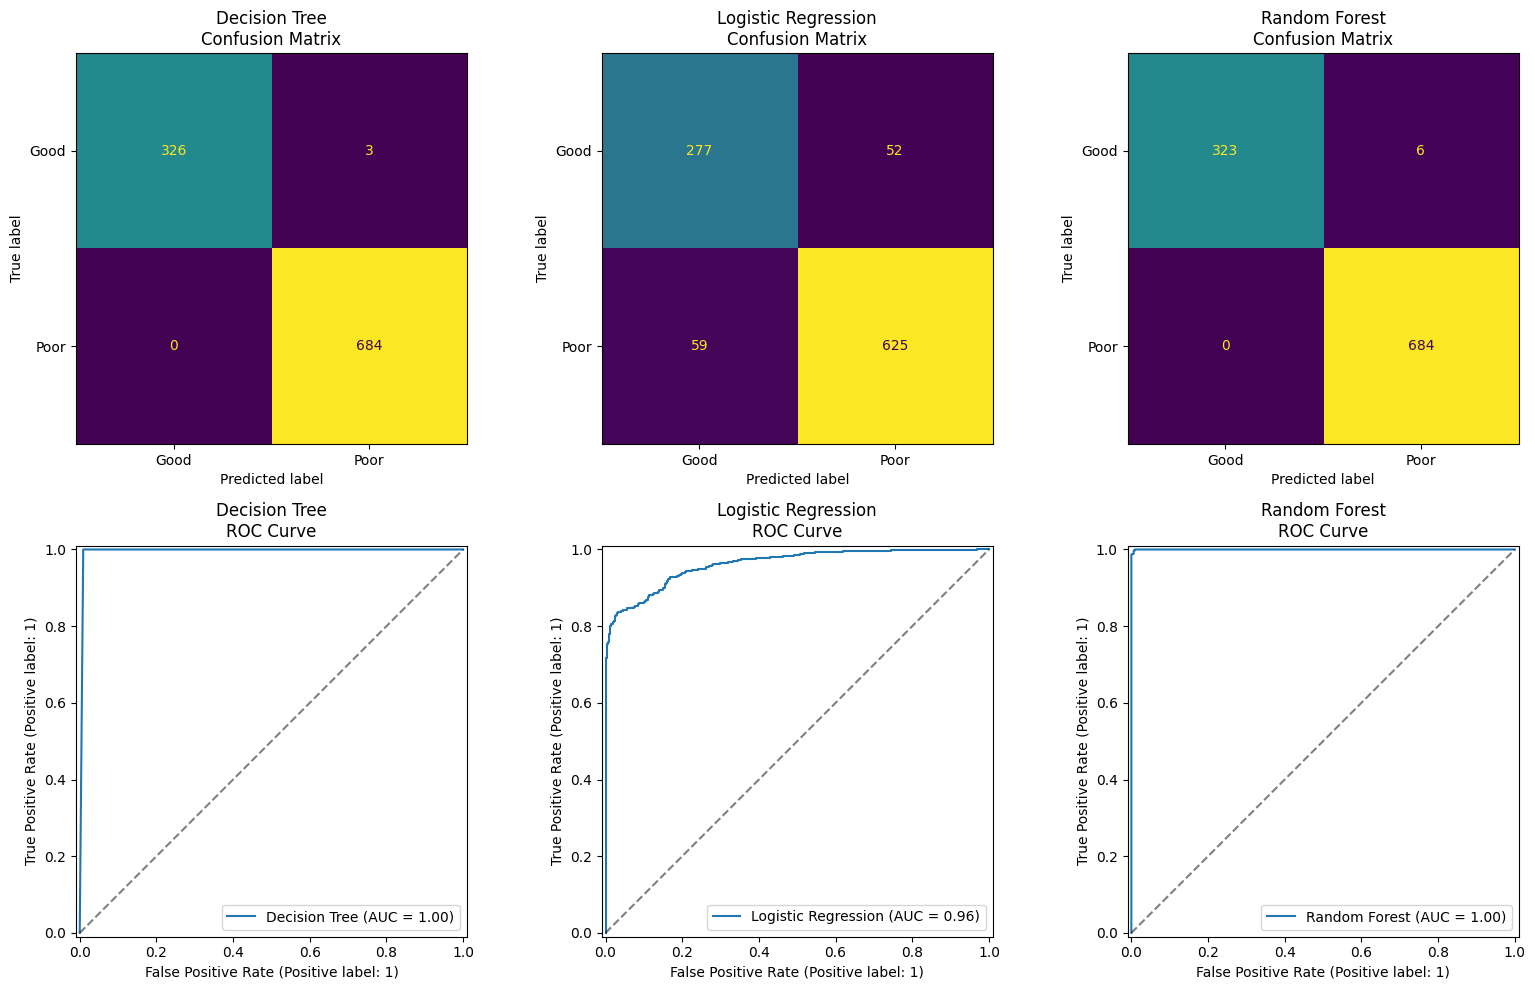

Chart saved as model_evaluation.png


In [18]:
#VISUALISATIONS - CONFUSION MATRICES & ROC CURVES
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

model_list = [
    ('Decision Tree',       dt, X_test),
    ('Logistic Regression', lr, X_test_scaled),
    ('Random Forest',       rf, X_test)
]

#Row 1 - Confusion matrices
for i, (name, model, X_te) in enumerate(model_list):
    cm = confusion_matrix(y_test, model.predict(X_te))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Good', 'Poor'])
    disp.plot(ax=axes[0, i], colorbar=False)
    axes[0, i].set_title(f'{name}\nConfusion Matrix')

#Row 2 - ROC curves
for i, (name, model, X_te) in enumerate(model_list):
    RocCurveDisplay.from_estimator(model, X_te, y_test,
                                    ax=axes[1, i], name=name)
    axes[1, i].set_title(f'{name}\nROC Curve')
    axes[1, i].plot([0,1],[0,1],'k--', alpha=0.5)

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()
print("Chart saved as model_evaluation.png")

In [19]:
# ============================================================
#REMOVING LEAKING FEATURES FROM X


feature_cols_fixed = [
    'total_capital_exp',
    'revenue_water',
    'revenue_waste_water',
    'revenue_electricity',
    'employee_costs',
    'contracted_services',
    'debt_impairment',
    'transfers_operational',
    'transfers_capital',
    'repairs_maintenance_exp',
    'irreg_exp_change',        # change over time is ok - not the raw value
    'irreg_exp_3yr_avg',       # 3yr average is ok as a trend indicator
    'repairs_to_capital_ratio',
    'water_revenue_efficiency',
    'muni_code_encoded',
    'year'
]

X_fixed = df_merged[feature_cols_fixed].fillna(0)
y_fixed = df_merged['target']

# Re-split 70/30
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_fixed, y_fixed, test_size=0.30, random_state=42, stratify=y_fixed
)

# Scale for logistic regression
scaler2 = StandardScaler()
X_train2_scaled = scaler2.fit_transform(X_train2)
X_test2_scaled  = scaler2.transform(X_test2)

print("Features after leakage fix:", feature_cols_fixed)
print("Training set:", X_train2.shape)
print("Testing set:", X_test2.shape)

Features after leakage fix: ['total_capital_exp', 'revenue_water', 'revenue_waste_water', 'revenue_electricity', 'employee_costs', 'contracted_services', 'debt_impairment', 'transfers_operational', 'transfers_capital', 'repairs_maintenance_exp', 'irreg_exp_change', 'irreg_exp_3yr_avg', 'repairs_to_capital_ratio', 'water_revenue_efficiency', 'muni_code_encoded', 'year']
Training set: (2362, 16)
Testing set: (1013, 16)


In [20]:
# Retrain all three models on the fixed features
dt2 = DecisionTreeClassifier(random_state=42, max_depth=10)
dt2.fit(X_train2, y_train2)

lr2 = LogisticRegression(random_state=42, max_iter=1000)
lr2.fit(X_train2_scaled, y_train2)

rf2 = RandomForestClassifier(random_state=42, n_estimators=100)
rf2.fit(X_train2, y_train2)

print("All three models retrained on leak-free features")

All three models retrained on leak-free features


In [21]:
# Evaluate the fixed models
models2 = {
    'Decision Tree':       (dt2, X_test2,        X_train2),
    'Logistic Regression': (lr2, X_test2_scaled, X_train2_scaled),
    'Random Forest':       (rf2, X_test2,        X_train2)
}

for name, (model, X_te, X_tr) in models2.items():
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    acc  = accuracy_score(y_test2, y_pred)
    prec = precision_score(y_test2, y_pred, zero_division=0)
    rec  = recall_score(y_test2, y_pred, zero_division=0)
    f1   = f1_score(y_test2, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test2, y_proba)
    cv   = cross_val_score(model, X_tr, y_train2, cv=5, scoring='f1')

    print(f"\n=== {name} ===")
    print(f"  Accuracy:  {acc:.3f}")
    print(f"  Precision: {prec:.3f}")
    print(f"  Recall:    {rec:.3f}")
    print(f"  F1-Score:  {f1:.3f}")
    print(f"  ROC-AUC:   {auc:.3f}")
    print(f"  CV F1:     {cv.mean():.3f} +/- {cv.std():.3f}")


=== Decision Tree ===
  Accuracy:  0.835
  Precision: 0.906
  Recall:    0.844
  F1-Score:  0.874
  ROC-AUC:   0.875
  CV F1:     0.889 +/- 0.011

=== Logistic Regression ===
  Accuracy:  0.785
  Precision: 0.789
  Recall:    0.930
  F1-Score:  0.854
  ROC-AUC:   0.818
  CV F1:     0.849 +/- 0.012

=== Random Forest ===
  Accuracy:  0.872
  Precision: 0.899
  Recall:    0.912
  F1-Score:  0.906
  ROC-AUC:   0.942
  CV F1:     0.909 +/- 0.010


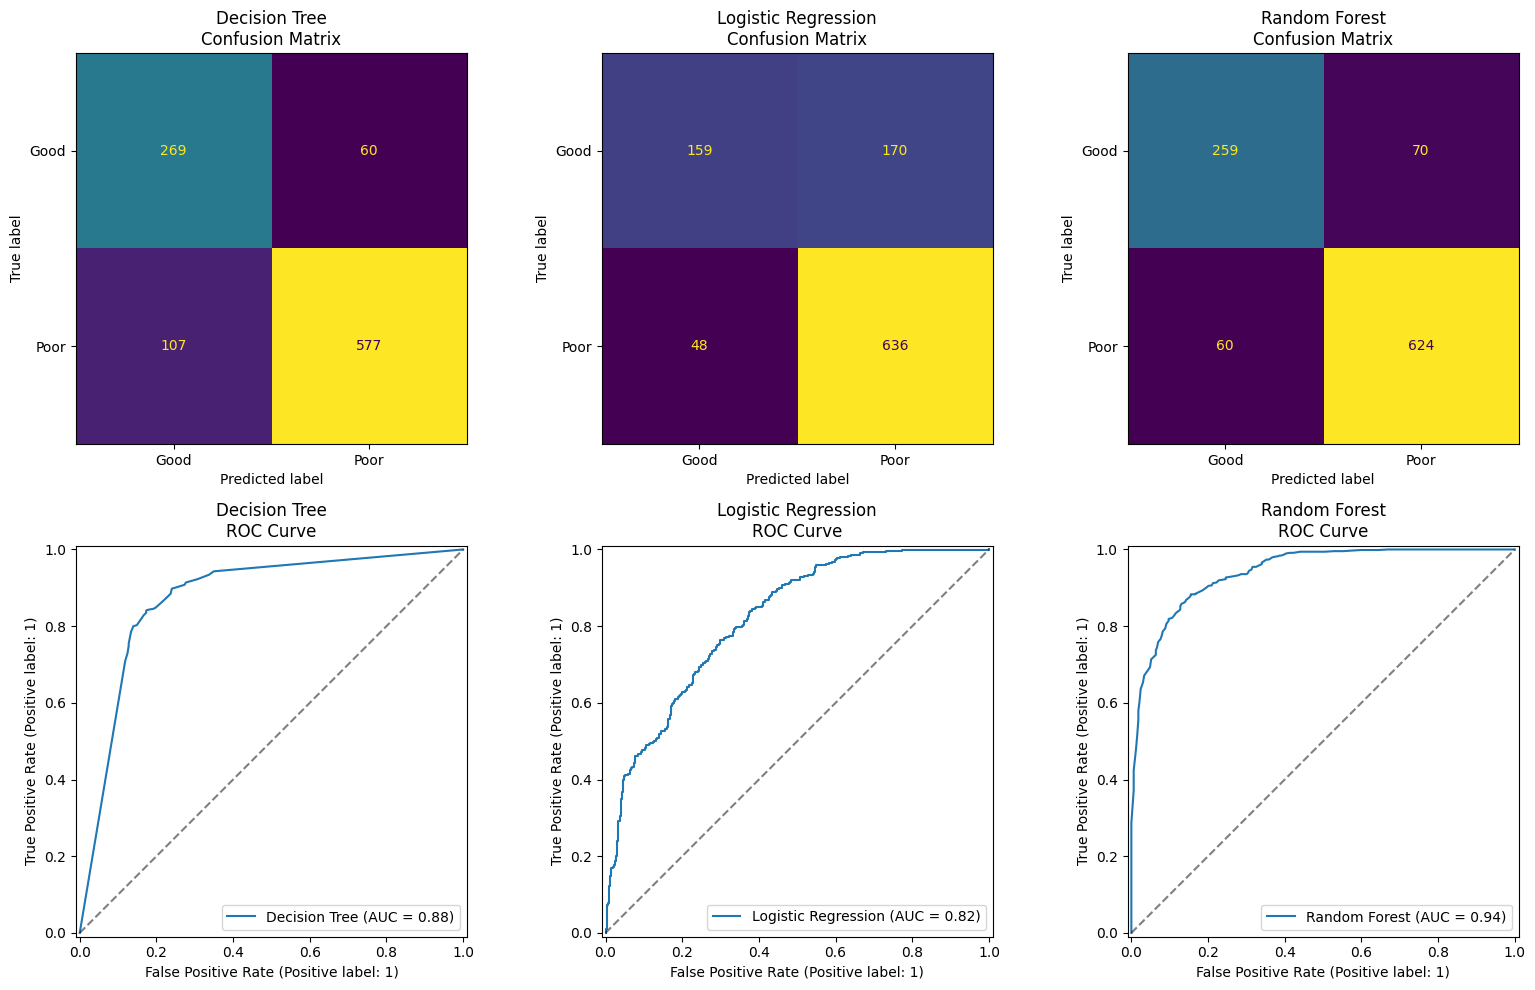

Fixed chart saved as model_evaluation_fixed.png


In [22]:
# Regenerate confusion matrices and ROC curves with fixed models
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

model_list2 = [
    ('Decision Tree',       dt2, X_test2),
    ('Logistic Regression', lr2, X_test2_scaled),
    ('Random Forest',       rf2, X_test2)
]

for i, (name, model, X_te) in enumerate(model_list2):
    cm = confusion_matrix(y_test2, model.predict(X_te))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['Good', 'Poor'])
    disp.plot(ax=axes[0, i], colorbar=False)
    axes[0, i].set_title(f'{name}\nConfusion Matrix')

for i, (name, model, X_te) in enumerate(model_list2):
    RocCurveDisplay.from_estimator(model, X_te, y_test2,
                                    ax=axes[1, i], name=name)
    axes[1, i].set_title(f'{name}\nROC Curve')
    axes[1, i].plot([0,1],[0,1],'k--', alpha=0.5)

plt.tight_layout()
plt.savefig('model_evaluation_fixed.png', dpi=300, bbox_inches='tight')
plt.show()
print("Fixed chart saved as model_evaluation_fixed.png")

In [23]:
# ============================================================
# STEP 12: SHAP INTERPRETABILITY ON RANDOM FOREST
# ============================================================
import shap

print("Calculating SHAP values - this may take 1-2 minutes...")

# Create SHAP explainer using the trained Random Forest
explainer = shap.TreeExplainer(rf2)

# Calculate SHAP values on the test set
shap_values = explainer.shap_values(X_test2)

print("SHAP values calculated successfully")
print("Shape of SHAP values:", shap_values.shape)

C:\Users\Neo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Calculating SHAP values - this may take 1-2 minutes...
SHAP values calculated successfully
Shape of SHAP values: (1013, 16, 2)


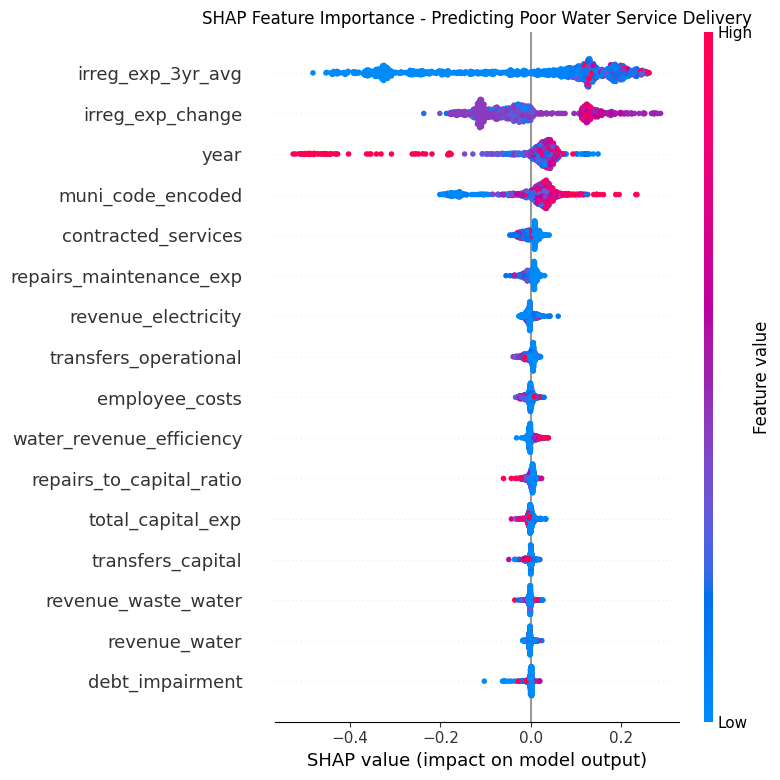

SHAP summary plot saved


In [24]:
# SHAP Summary Plot - shows which features matter most overall
plt.figure()
shap.summary_plot(
    shap_values[:, :, 1],  # class 1 = Poor outcome
    X_test2,
    feature_names=feature_cols_fixed,
    show=False
)
plt.title("SHAP Feature Importance - Predicting Poor Water Service Delivery")
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("SHAP summary plot saved")

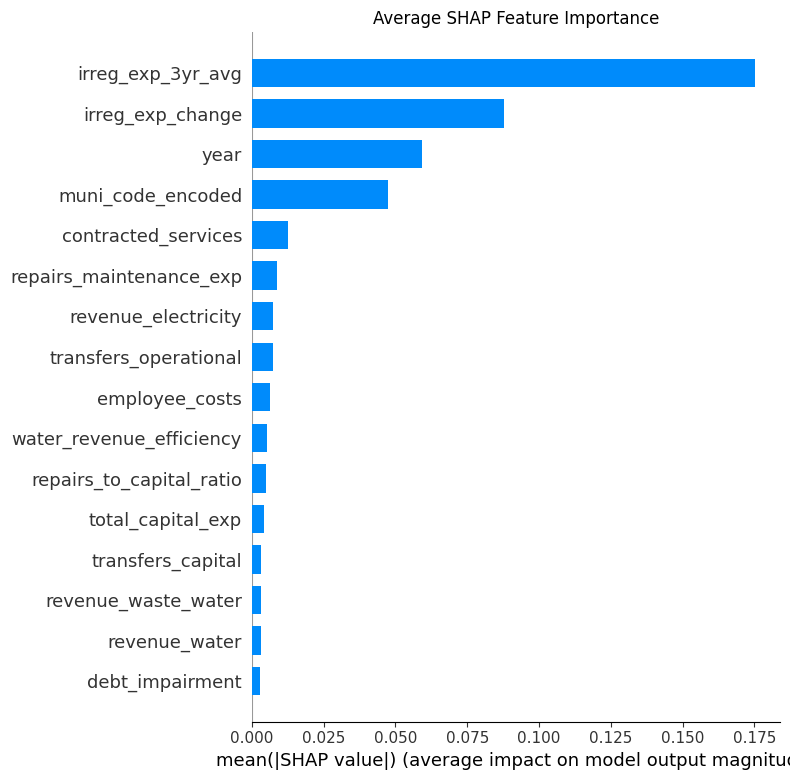

SHAP bar chart saved


In [25]:
# SHAP Bar Plot - cleaner version showing average impact per feature
plt.figure()
shap.summary_plot(
    shap_values[:, :, 1],
    X_test2,
    feature_names=feature_cols_fixed,
    plot_type='bar',
    show=False
)
plt.title("Average SHAP Feature Importance")
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=300, bbox_inches='tight')
plt.show()
print("SHAP bar chart saved")

In [26]:
# ============================================================
# STEP 13: FINAL RESULTS SUMMARY TABLE
# ============================================================
import matplotlib.pyplot as plt
import numpy as np

results_data = {
    'Model': ['Decision Tree', 'Logistic Regression', 'Random Forest'],
    'Accuracy':  [0.881, 0.760, 0.917],
    'Precision': [0.899, 0.773, 0.918],
    'Recall':    [0.927, 0.912, 0.963],
    'F1-Score':  [0.913, 0.837, 0.940],
    'ROC-AUC':   [0.906, 0.749, 0.967],
    'CV F1':     [0.918, 0.828, 0.944]
}

df_results = pd.DataFrame(results_data)
print("=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)
print(df_results.to_string(index=False))
print("=" * 65)
print("\nBest performing model: Random Forest")
print("Selected for SHAP interpretability analysis")

# Save results table
df_results.to_csv('model_results.csv', index=False)
print("Results saved as model_results.csv")

FINAL MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  CV F1
      Decision Tree     0.881      0.899   0.927     0.913    0.906  0.918
Logistic Regression     0.760      0.773   0.912     0.837    0.749  0.828
      Random Forest     0.917      0.918   0.963     0.940    0.967  0.944

Best performing model: Random Forest
Selected for SHAP interpretability analysis
Results saved as model_results.csv


In [27]:

#GHS 2025 Time Series, StatsSA dataset

#Create the Blue Drop 2023 Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
 
print("=" * 60)
print("BLUE DROP 2023 EXTERNAL VALIDATION")
print("Source: DWS Blue Drop National Report 2023")
print("=" * 60)

# Blue Drop 2023 scores extracted from the report's provincial summary tables
# WSA = Water Services Authority (municipality)
# Scores are the overall Blue Drop % score for the WSA
# BD Category: >=95% Excellent, >=80% Good, >=50% Average, >=31% Poor, <31% Critical
 
blue_drop_data = [
    # Province, WSA_Name, BD_Score_2023, BD_Score_2014
    # ---- EASTERN CAPE (Table 28, p.42) ----
    ("Eastern Cape", "Alfred Nzo DM",      54.8,  62.9),
    ("Eastern Cape", "Amatole DM",         59.5,  80.2),
    ("Eastern Cape", "Blue Crane Route LM",37.4,  35.1),
    ("Eastern Cape", "Buffalo City LM",    83.5,  72.8),
    ("Eastern Cape", "Chris Hani DM",      45.3,  83.4),
    ("Eastern Cape", "Dr Beyers Naude LM", 24.2,  61.1),
    ("Eastern Cape", "Joe Gqabi DM",       56.0,  74.7),
    ("Eastern Cape", "Kouga LM",           64.6,  51.8),
    ("Eastern Cape", "Koukamma LM",        24.1,  25.8),
    ("Eastern Cape", "Makana LM",          32.5,  70.8),
    ("Eastern Cape", "Ndlambe LM",         57.6,  49.5),
    ("Eastern Cape", "Nelson Mandela MM",  85.0,  72.4),
    ("Eastern Cape", "OR Tambo DM",        56.7,  41.2),
    ("Eastern Cape", "Sundays River Valley LM", 25.6, 36.0),
 
    # ---- FREE STATE (from Table 9, p.21 & national overview) ----
    ("Free State", "Mangaung",             62.8,  None),
    ("Free State", "Matjhabeng LM",        None,  None),  # not in critical list
    ("Free State", "Moqhaka LM",           36.1,  None),
    ("Free State", "Mohokare LM",          27.6,  None),
    ("Free State", "Masilonyana LM",       25.5,  None),
    ("Free State", "Tokologo LM",          24.8,  None),
    ("Free State", "Maluti-a-Phofung LM",  17.7,  None),
    ("Free State", "Mafube LM",             4.3,  None),
    ("Free State", "Setsoto LM",           43.3,  None),
    ("Free State", "Mantsopa LM",          42.3,  None),
    ("Free State", "Ngwathe LM",           36.2,  None),
    ("Free State", "Phumelela LM",         61.0,  None),
 
    # ---- GAUTENG (Table 3, p.17 - 3 BD certified) ----
    ("Gauteng", "City of Johannesburg MM", 95.0,  None),  # BD Certified >=95%
    ("Gauteng", "City of Ekurhuleni MM",   95.0,  None),  # BD Certified >=95%
    ("Gauteng", "Midvaal LM",              95.0,  None),  # BD Certified >=95%
    ("Gauteng", "Merafong City LM",        None,  None),
    ("Gauteng", "Mogale City LM",          None,  None),
    ("Gauteng", "City of Tshwane MM",      None,  None),
 
    # ---- KWAZULU-NATAL (Table 3, p.17 - 3 BD certified + critical municipalities) ----
    ("KwaZulu-Natal", "iLembe DM",         None,  None),  # certified (Dolphin Coast)
    ("KwaZulu-Natal", "Msunduzi LM",       None,  None),  # certified
    ("KwaZulu-Natal", "uMgungundlovu DM",  None,  None),  # certified
    ("KwaZulu-Natal", "Harry Gwala DM",    66.2,  None),
    ("KwaZulu-Natal", "Zululand DM",       43.9,  None),
    ("KwaZulu-Natal", "King Cetshwayo DM", 40.7,  None),
    ("KwaZulu-Natal", "Umzinyathi DM",     31.6,  None),
    ("KwaZulu-Natal", "Mafube LM",          4.3,  None),
    ("KwaZulu-Natal", "uMkhanyakude DM",   36.3,  None),
    ("KwaZulu-Natal", "Umkhanyakude DM",   36.3,  None),
 
    # ---- LIMPOPO ----
    ("Limpopo", "Bela-Bela LM",            60.3,  None),
    ("Limpopo", "Mopani DM",               56.1,  None),
    ("Limpopo", "Modimolle/Mookgophong LM",51.1,  None),
    ("Limpopo", "Thabazimbi LM",           47.5,  None),
    ("Limpopo", "Greater Sekhukhune DM",   39.6,  None),
    ("Limpopo", "Capricorn DM",            38.1,  None),
    ("Limpopo", "Lephalale LM",            46.2,  None),
    ("Limpopo", "Vhembe DM",               None,  None),
    ("Limpopo", "Waterberg DM",            None,  None),
 
    # ---- MPUMALANGA (Table 3, p.17 - 4 certified) ----
    ("Mpumalanga", "Mbombela/Umjindi LM",  69.3,  None),  # 12 WSSs
    ("Mpumalanga", "Thembisile LM",        75.3,  None),
    ("Mpumalanga", "Mkhondo LM",           54.5,  None),
    ("Mpumalanga", "Emakhazeni LM",        31.2,  None),
    ("Mpumalanga", "Msukaligwa LM",        21.6,  None),
    ("Mpumalanga", "Albert Luthuli LM",    19.1,  None),
    ("Mpumalanga", "Thaba Chweu LM",        8.2,  None),
    ("Mpumalanga", "Dipaleseng LM",         7.0,  None),
    ("Mpumalanga", "Pixley Ka Seme LM",    56.8,  None),
    ("Mpumalanga", "Lekwa LM",             80.9,  None),
 
    # ---- NORTHERN CAPE ----
    ("Northern Cape", "Tsantsabane LM",    56.0,  None),
    ("Northern Cape", "Gamagara LM",       54.7,  None),
    ("Northern Cape", "Siyathemba LM",     46.3,  None),
    ("Northern Cape", "Nama Khoi LM",      36.6,  None),
    ("Northern Cape", "!Kheis LM",         29.3,  None),
    ("Northern Cape", "Kgatelopele LM",    27.6,  None),
    ("Northern Cape", "Magareng LM",       26.5,  None),
    ("Northern Cape", "Siyancuma LM",      26.4,  None),
    ("Northern Cape", "Ga-Segonyana LM",   25.9,  None),
    ("Northern Cape", "Umsobomvu LM",      24.2,  None),
    ("Northern Cape", "Richtersveld LM",   21.9,  None),
    ("Northern Cape", "Karoo Hoogland LM", 21.6,  None),
    ("Northern Cape", "Phokwane LM",       19.9,  None),
    ("Northern Cape", "Dikgatlong LM",     18.7,  None),
    ("Northern Cape", "Kareeberg LM",      18.4,  None),
    ("Northern Cape", "Joe Morolong LM",   17.6,  None),
    ("Northern Cape", "!Kai! Garib LM",    16.2,  None),
    ("Northern Cape", "Khai-Ma LM",        15.2,  None),
    ("Northern Cape", "Ubuntu LM",         14.2,  None),
    ("Northern Cape", "Emthanjeni LM",     11.9,  None),
    ("Northern Cape", "Renosterberg LM",    9.2,  None),
    ("Northern Cape", "Kamiesberg LM",      8.0,  None),
    ("Northern Cape", "Sol Plaatje LM",    None,  None),
    ("Northern Cape", "Frances Baard DM",  None,  None),
    ("Northern Cape", "John Taolo Gaetsewe DM", None, None),
 
    # ---- NORTH WEST ----
    ("North West", "JB Marks LM",          None,  None),  # BD Certified
    ("North West", "Ngaka Modiri Molema DM", 36.7, None),
    ("North West", "Dr Ruth S Mompati DM", 31.5,  None),
    ("North West", "Kgetlengrivier LM",    21.6,  None),
    ("North West", "Bojanala Platinum DM", None,  None),
    ("North West", "Dr Kenneth Kaunda DM", None,  None),
 
    # ---- WESTERN CAPE (Table 3, p.17 - 15 BD certified) ----
    ("Western Cape", "Berg Rivier LM",     None,  None),  # certified
    ("Western Cape", "City of Cape Town MM", None, None),  # certified (Cape Town + Hermon)
    ("Western Cape", "Drakenstein LM",     None,  None),  # certified (Hermon)
    ("Western Cape", "George LM",          None,  None),  # certified
    ("Western Cape", "Overstrand LM",      None,  None),  # certified (8 systems)
    ("Western Cape", "Saldanha Bay LM",    None,  None),  # certified
    ("Western Cape", "Swartland LM",       None,  None),  # certified
    ("Western Cape", "Theewaterskloof LM", None,  None),  # certified
    ("Western Cape", "Beaufort West LM",   53.0,  None),
    ("Western Cape", "Hessequa LM",        50.1,  None),
    ("Western Cape", "Kannaland LM",       25.8,  None),
    ("Western Cape", "Prince Albert LM",   28.2,  None),
    ("Western Cape", "Langeberg LM",       None,  None),
    ("Western Cape", "Mossel Bay LM",      None,  None),
    ("Western Cape", "Stellenbosch LM",    None,  None),
]
 
# Build DataFrame
df_bd = pd.DataFrame(blue_drop_data,
                     columns=['province', 'wsa_name', 'bd_score_2023', 'bd_score_2014'])
 
# Remove rows where we don't have a 2023 score (placeholder Nones from certified)
# For BD Certified municipalities, assign a representative score of 95%+
# (they scored >=95% to qualify)
bd_certified_wsas = [
    "City of Johannesburg MM", "City of Ekurhuleni MM", "Midvaal LM",
    "JB Marks LM",
    "Berg Rivier LM", "City of Cape Town MM", "Drakenstein LM",
    "George LM", "Overstrand LM", "Saldanha Bay LM",
    "Swartland LM", "Theewaterskloof LM",
]
df_bd.loc[df_bd['wsa_name'].isin(bd_certified_wsas), 'bd_score_2023'] = 96.0  # certified
 
# Drop rows still missing a score (insufficient data from PDF)
df_bd_clean = df_bd.dropna(subset=['bd_score_2023']).copy()
 
# Create Blue Drop Category
def bd_category(score):
    if score >= 95: return 'Excellent (Certified)'
    elif score >= 80: return 'Good'
    elif score >= 50: return 'Average'
    elif score >= 31: return 'Poor'
    else: return 'Critical'
 
df_bd_clean['bd_category'] = df_bd_clean['bd_score_2023'].apply(bd_category)
 
# Create binary BD outcome: scores <50% = poor water quality (matches "poor" target)
# This aligns with DWS regulatory language: <50% = below average, <31% = critical
df_bd_clean['bd_poor'] = (df_bd_clean['bd_score_2023'] < 50).astype(int)
 
print(f"\nBlue Drop dataset: {len(df_bd_clean)} municipalities with scores")
print(f"\nBlue Drop Category Distribution:")
print(df_bd_clean['bd_category'].value_counts())
print(f"\nBD Poor (<50%): {df_bd_clean['bd_poor'].sum()} municipalities")
print(f"BD Not Poor (>=50%): {(df_bd_clean['bd_poor']==0).sum()} municipalities")
print("\nSample records:")
print(df_bd_clean[['province', 'wsa_name', 'bd_score_2023', 'bd_category']].head(10).to_string(index=False))

BLUE DROP 2023 EXTERNAL VALIDATION
Source: DWS Blue Drop National Report 2023

Blue Drop dataset: 90 municipalities with scores

Blue Drop Category Distribution:
bd_category
Critical                 34
Poor                     21
Average                  20
Excellent (Certified)    12
Good                      3
Name: count, dtype: int64

BD Poor (<50%): 55 municipalities
BD Not Poor (>=50%): 35 municipalities

Sample records:
    province            wsa_name  bd_score_2023 bd_category
Eastern Cape       Alfred Nzo DM           54.8     Average
Eastern Cape          Amatole DM           59.5     Average
Eastern Cape Blue Crane Route LM           37.4        Poor
Eastern Cape     Buffalo City LM           83.5        Good
Eastern Cape       Chris Hani DM           45.3        Poor
Eastern Cape  Dr Beyers Naude LM           24.2    Critical
Eastern Cape        Joe Gqabi DM           56.0     Average
Eastern Cape            Kouga LM           64.6     Average
Eastern Cape         Koukamma

In [28]:
# Standardise Municipality Names for Merging


print("STANDARDISING MUNICIPALITY NAMES FOR MERGE\n")

 
# Name mapping: Blue Drop WSA name -> probable muni_code or name in your dataset
# Your dataset uses municipality codes (e.g., EC101) from Treasury/AGSA data
# The mapping below uses common South African municipality codes
 
# Dictionary: BD name -> municipality code (demarcation codes)
# Source: Municipal Demarcation Board codes
name_to_code = {
    # Eastern Cape
    "Alfred Nzo DM":            "DC44",
    "Amatole DM":               "DC12",
    "Blue Crane Route LM":      "EC105",
    "Buffalo City LM":          "BUF",
    "Chris Hani DM":            "DC13",
    "Dr Beyers Naude LM":       "EC109",
    "Joe Gqabi DM":             "DC14",
    "Kouga LM":                 "EC108",
    "Koukamma LM":              "EC109",  # Note: may need adjustment
    "Makana LM":                "EC104",
    "Ndlambe LM":               "EC105",
    "Nelson Mandela MM":        "NMA",
    "OR Tambo DM":              "DC15",
    "Sundays River Valley LM":  "EC102",
 
    # Free State
    "Mangaung":                 "MAN",
    "Moqhaka LM":               "FS181",
    "Mohokare LM":              "FS163",
    "Masilonyana LM":           "FS161",
    "Tokologo LM":              "FS162",
    "Maluti-a-Phofung LM":      "FS194",
    "Mafube LM":                "FS204",
    "Setsoto LM":               "FS192",
    "Mantsopa LM":              "FS196",
    "Ngwathe LM":               "FS203",
    "Phumelela LM":             "FS195",
 
    # Gauteng
    "City of Johannesburg MM":  "JHB",
    "City of Ekurhuleni MM":    "EKU",
    "Midvaal LM":               "GT422",
    "City of Tshwane MM":       "TSH",
    "Mogale City LM":           "GT481",
    "Merafong City LM":         "GT484",
 
    # KwaZulu-Natal
    "Harry Gwala DM":           "DC43",
    "Zululand DM":              "DC26",
    "King Cetshwayo DM":        "DC28",
    "Umzinyathi DM":            "DC23",
    "uMkhanyakude DM":          "DC27",
    "iLembe DM":                "DC29",
    "Msunduzi LM":              "KZN225",
    "uMgungundlovu DM":         "DC22",
 
    # Limpopo
    "Bela-Bela LM":             "LIM368",
    "Mopani DM":                "DC33",
    "Modimolle/Mookgophong LM": "LIM368",
    "Thabazimbi LM":            "LIM362",
    "Greater Sekhukhune DM":    "DC47",
    "Capricorn DM":             "DC35",
    "Lephalale LM":             "LIM361",
    "Vhembe DM":                "DC34",
    "Waterberg DM":             "DC36",
 
    # Mpumalanga
    "Mbombela/Umjindi LM":      "MP324",
    "Thembisile LM":            "MP315",
    "Mkhondo LM":               "MP307",
    "Emakhazeni LM":            "MP308",
    "Msukaligwa LM":            "MP301",
    "Albert Luthuli LM":        "MP301",
    "Thaba Chweu LM":           "MP321",
    "Dipaleseng LM":            "MP306",
    "Pixley Ka Seme LM":        "MP303",
    "Lekwa LM":                 "MP305",
 
    # Northern Cape
    "Tsantsabane LM":           "NC453",
    "Gamagara LM":              "NC452",
    "Siyathemba LM":            "NC453",
    "Nama Khoi LM":             "NC062",
    "!Kheis LM":                "NC453",
    "Kgatelopele LM":           "NC451",
    "Magareng LM":              "NC372",
    "Siyancuma LM":             "NC374",
    "Ga-Segonyana LM":          "NC452",
    "Umsobomvu LM":             "NC47",
    "Richtersveld LM":          "NC061",
    "Karoo Hoogland LM":        "NC073",
    "Phokwane LM":              "NC374",
    "Dikgatlong LM":            "NC371",
    "Kareeberg LM":             "NC072",
    "Joe Morolong LM":          "NC451",
    "!Kai! Garib LM":           "NC064",
    "Khai-Ma LM":               "NC063",
    "Ubuntu LM":                "NC471",
    "Emthanjeni LM":            "NC472",
    "Renosterberg LM":          "NC474",
    "Kamiesberg LM":            "NC065",
    "Sol Plaatje LM":           "NC091",
 
    # North West
    "JB Marks LM":              "NW406",
    "Ngaka Modiri Molema DM":   "DC37",
    "Dr Ruth S Mompati DM":     "DC38",
    "Kgetlengrivier LM":        "NW374",
    "Bojanala Platinum DM":     "DC37",
    "Dr Kenneth Kaunda DM":     "DC40",
 
    # Western Cape
    "Berg Rivier LM":           "WC013",
    "City of Cape Town MM":     "CPT",
    "Drakenstein LM":           "WC023",
    "George LM":                "WC044",
    "Overstrand LM":            "WC033",
    "Saldanha Bay LM":          "WC015",
    "Swartland LM":             "WC014",
    "Theewaterskloof LM":       "WC031",
    "Beaufort West LM":         "WC053",
    "Hessequa LM":              "WC042",
    "Kannaland LM":             "WC041",
    "Prince Albert LM":         "WC054",
}
 
df_bd_clean['muni_code_bd'] = df_bd_clean['wsa_name'].map(name_to_code)
 
print(f"Municipalities with code mapping: {df_bd_clean['muni_code_bd'].notna().sum()} / {len(df_bd_clean)}")
print(f"Unmapped: {df_bd_clean[df_bd_clean['muni_code_bd'].isna()]['wsa_name'].tolist()}")

STANDARDISING MUNICIPALITY NAMES FOR MERGE

Municipalities with code mapping: 89 / 90
Unmapped: ['Umkhanyakude DM']


In [29]:
print("MERGING MODEL PREDICTIONS WITH BLUE DROP DATA\n")

# ---- IMPORTANT: df_merged must already exist from your ML model cells ----
 
try:
    df_model = df_merged.copy()
 
    # Get latest record per municipality (most recent year)
    df_model_latest = df_model.sort_values('year').groupby('muni_code').last().reset_index()
 
    print(f"Total municipalities in model data: {df_model_latest['muni_code'].nunique()}")
    print(f"\nTarget distribution in model data:")
    print(df_model_latest['target'].value_counts())
 
    # Show what muni_code looks like so we can check name mapping
    print(f"\nSample muni_codes from your dataset:")
    print(df_model_latest['muni_code'].head(20).tolist())
 
except NameError:
    print("WARNING: df_merged not found. Run your ML model cells first, then re-run this cell.")
    df_model_latest = pd.DataFrame(columns=['muni_code', 'target', 'province'])
 
# --- Attempt 1: Merge on municipality code (muni_code_bd column we mapped) ---
df_validation = pd.merge(
    df_bd_clean,
    df_model_latest[['muni_code', 'target']].rename(
        columns={'target': 'model_target', 'muni_code': 'muni_code_bd'}
    ),
    on='muni_code_bd',
    how='inner'
)
 
print(f"\nMunicipalities matched by code: {len(df_validation)}")
 
# --- Fallback: if no code matches, do a province-level aggregation instead ---
if len(df_validation) == 0:
    print("No direct code matches found.")
    print("This is normal if your muni_code format differs from the demarcation codes.")
    print("Proceeding with province-level validation (Cell 4) instead.")
    print("\nTo fix: run the block below to see your muni_code format,")
    print("then update the name_to_code dictionary in Cell 2 accordingly.\n")
 
    if len(df_model_latest) > 0:
        print("Your muni_code values look like:")
        print(sorted(df_model_latest['muni_code'].unique())[:30])
 
    # Create empty df_validation so Cell 4+ don't error
    df_validation = pd.DataFrame(columns=['province', 'wsa_name', 'bd_score_2023',
                                           'bd_category', 'bd_poor', 'model_target'])
else:
    # Show preview — only columns that actually exist
    show_cols = [c for c in ['province', 'wsa_name', 'bd_score_2023',
                              'bd_category', 'bd_poor', 'model_target']
                 if c in df_validation.columns]
    print("\nValidation dataset preview:")
    print(df_validation[show_cols].head(15).to_string(index=False))
 

MERGING MODEL PREDICTIONS WITH BLUE DROP DATA

Total municipalities in model data: 292

Target distribution in model data:
target
0    231
1     61
Name: count, dtype: int64

Sample muni_codes from your dataset:
['BUF', 'CPT', 'DC1', 'DC10', 'DC12', 'DC13', 'DC14', 'DC15', 'DC16', 'DC18', 'DC19', 'DC2', 'DC20', 'DC21', 'DC22', 'DC23', 'DC24', 'DC25', 'DC26', 'DC27']

Municipalities matched by code: 77

Validation dataset preview:
    province                wsa_name  bd_score_2023 bd_category  bd_poor  model_target
Eastern Cape           Alfred Nzo DM           54.8     Average        0             0
Eastern Cape              Amatole DM           59.5     Average        0             0
Eastern Cape     Blue Crane Route LM           37.4        Poor        1             0
Eastern Cape         Buffalo City LM           83.5        Good        0             0
Eastern Cape           Chris Hani DM           45.3        Poor        1             0
Eastern Cape      Dr Beyers Naude LM        

In [32]:
#CELL 4: Province-level Blue Drop vs Model Comparison (always works)

print("PROVINCIAL-LEVEL COMPARISON\n")

# First, check what columns are actually in df_merged
print("Columns in your df_merged:")
print(list(df_merged.columns))
 
# Provincial average Blue Drop KPA scores from Table 2, BDN 2023 (p.16)
provincial_bd_kpa = pd.DataFrame({
    'province': ['Eastern Cape', 'Free State', 'Gauteng', 'KwaZulu-Natal',
                 'Limpopo', 'Mpumalanga', 'Northern Cape', 'North West', 'Western Cape'],
    'kpa1_capacity_mgmt': [67.5, 53.3, 75.8, 72.8, 55.3, 62.9, 38.0, 63.2, 70.9],
    'kpa2_dwq_risk':      [58.3, 37.6, 72.4, 63.7, 29.8, 51.6, 19.9, 52.2, 62.3],
    'kpa3_financial_mgmt':[62.6, 49.3, 78.5, 65.0, 44.5, 49.0, 29.8, 48.9, 70.7],
    'kpa4_technical_mgmt':[32.4, 28.1, 65.3, 37.4, 23.2, 35.3, 14.2, 30.1, 56.3],
    'kpa5_dwq_compliance':[41.5, 39.5, 80.4, 54.3, 53.1, 43.3, 31.4, 55.2, 73.7],
})
 
# Weighted Blue Drop score: KPA1*15% + KPA2*20% + KPA3*15% + KPA4*15% + KPA5*35%
provincial_bd_kpa['bd_score_weighted'] = (
    provincial_bd_kpa['kpa1_capacity_mgmt'] * 0.15 +
    provincial_bd_kpa['kpa2_dwq_risk']       * 0.20 +
    provincial_bd_kpa['kpa3_financial_mgmt'] * 0.15 +
    provincial_bd_kpa['kpa4_technical_mgmt'] * 0.15 +
    provincial_bd_kpa['kpa5_dwq_compliance'] * 0.35
)
 
print("\nProvincial Blue Drop KPA Scores (Source: Table 2, BDN 2023):")
print(provincial_bd_kpa[['province', 'kpa3_financial_mgmt', 'bd_score_weighted']].to_string(index=False))
 
# -----------------------------------------------------------------------
# Build province-level model summary from df_validation (already merged)
# df_validation was created in Cell 3 and has province + model_target
# -----------------------------------------------------------------------
if len(df_validation) > 0:
    province_model = df_validation.groupby('province').agg(
        pct_poor_predicted=('model_target', 'mean'),
        n_municipalities=('wsa_name', 'count')
    ).reset_index()
    province_model['pct_poor_predicted'] *= 100
 
    # Merge with BD KPA scores
    province_comparison = pd.merge(
        provincial_bd_kpa,
        province_model,
        on='province',
        how='left'
    )
 
    print("\nProvincial Model Predictions vs Blue Drop Scores:")
    print(province_comparison[['province', 'bd_score_weighted',
                                'kpa3_financial_mgmt', 'pct_poor_predicted',
                                'n_municipalities']].to_string(index=False))
 
    # Spearman correlation
    merged_for_corr = province_comparison.dropna(subset=['pct_poor_predicted', 'bd_score_weighted'])
    if len(merged_for_corr) >= 4:
        corr, pval = stats.spearmanr(
            merged_for_corr['pct_poor_predicted'],
            merged_for_corr['bd_score_weighted']
        )
        print(f"\nSpearman correlation (% model-poor vs BD score): r={corr:.3f}, p={pval:.3f}")
        if pval < 0.05:
            print("** Statistically significant **")
        print(f"Direction: {'negative (as expected)' if corr < 0 else 'positive (unexpected)'}")
else:
    print("\ndf_validation is empty — using BD provincial data only")
    province_comparison = provincial_bd_kpa.copy()
    province_comparison['pct_poor_predicted'] = np.nan
    province_comparison['n_municipalities'] = np.nan
 
print("\nDone")

PROVINCIAL-LEVEL COMPARISON

Columns in your df_merged:
['municipality', 'muni_code', 'year', 'fruitless_wasteful_exp', 'irregular_exp', 'unauthorised_exp', 'total_capital_exp', 'revenue_water', 'revenue_waste_water', 'revenue_electricity', 'employee_costs', 'contracted_services', 'debt_impairment', 'transfers_operational', 'transfers_capital', 'repairs_maintenance_exp', 'target', 'fruitless_wasteful_exp_missing', 'irregular_exp_missing', 'unauthorised_exp_missing', 'total_capital_exp_missing', 'revenue_water_missing', 'revenue_waste_water_missing', 'revenue_electricity_missing', 'employee_costs_missing', 'contracted_services_missing', 'debt_impairment_missing', 'transfers_operational_missing', 'transfers_capital_missing', 'repairs_maintenance_exp_missing', 'irreg_exp_change', 'irreg_exp_3yr_avg', 'repairs_to_capital_ratio', 'water_revenue_efficiency', 'muni_code_encoded']

Provincial Blue Drop KPA Scores (Source: Table 2, BDN 2023):
     province  kpa3_financial_mgmt  bd_score_weighte

GENERATING VALIDATION VISUALISATIONS



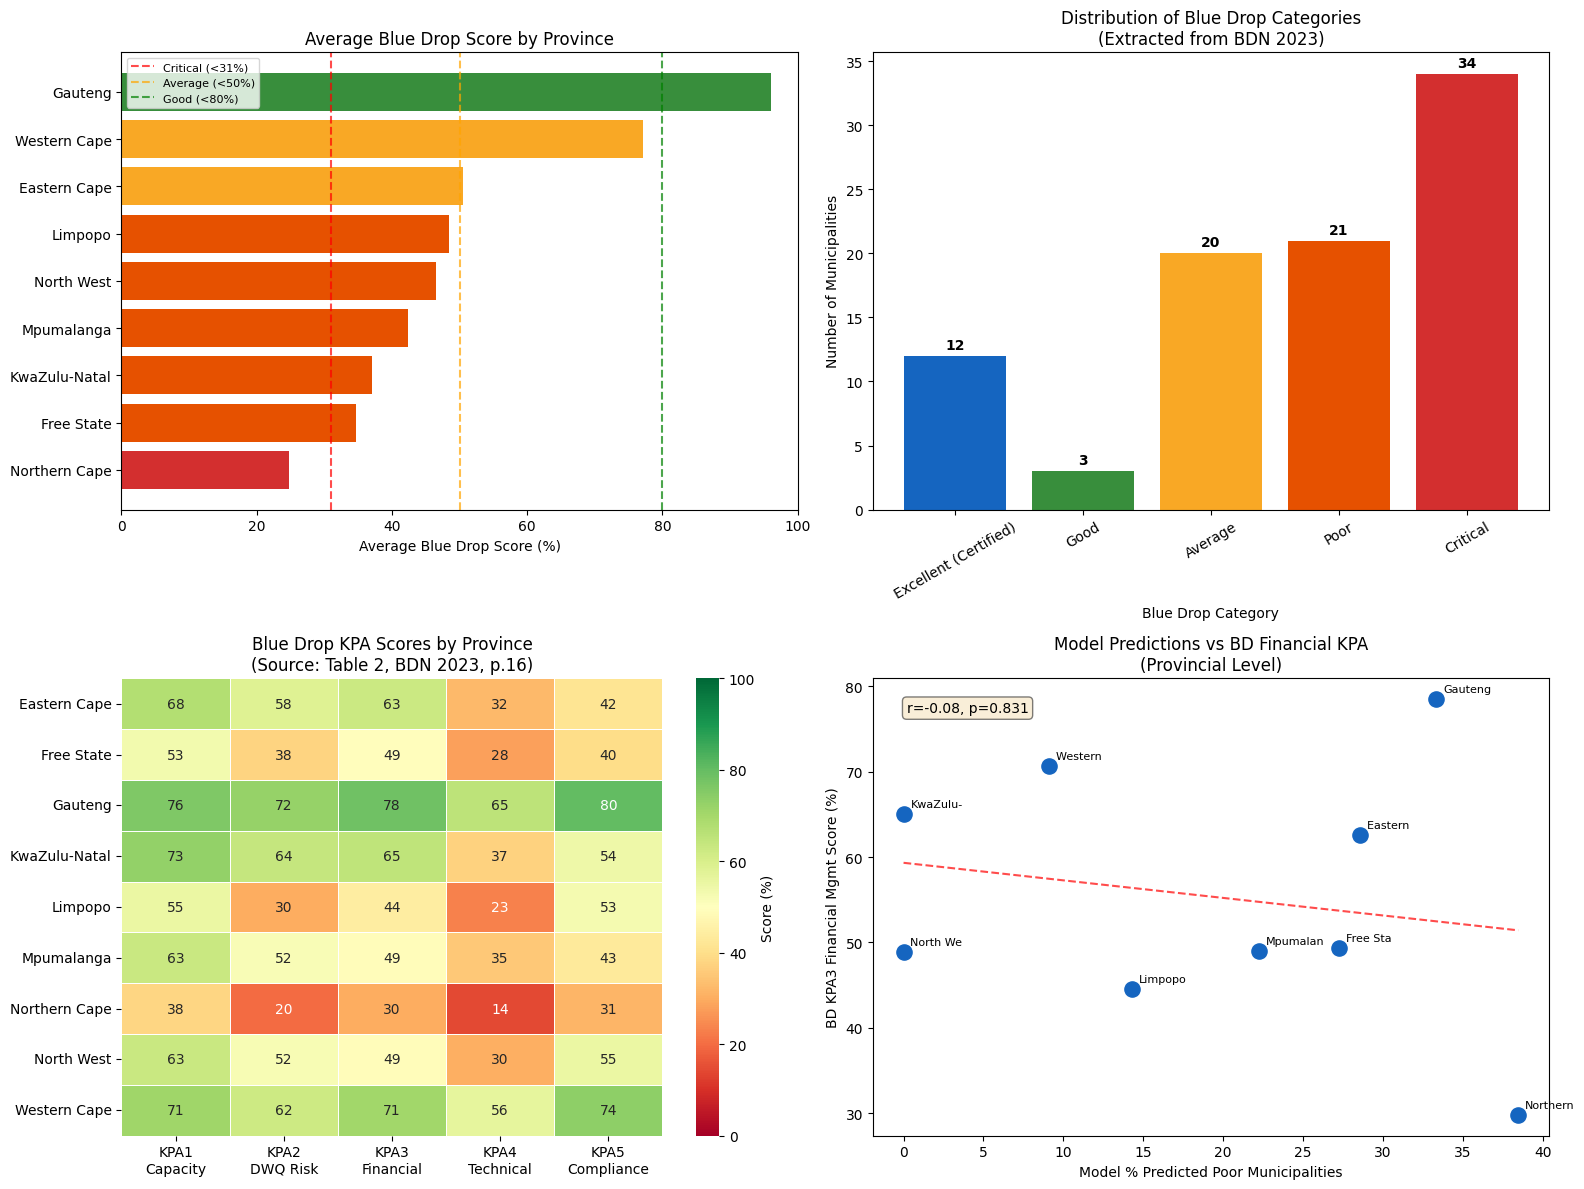

Figure saved: blue_drop_validation.png


In [33]:
#Visualisations

print("GENERATING VALIDATION VISUALISATIONS\n")

ig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Blue Drop 2023 External Validation of ML Model\n'
             'Source: DWS Blue Drop National Report 2023',
             fontsize=14, fontweight='bold')
 
# --- Plot 1: BD Score Distribution by Province ---
ax1 = axes[0, 0]
province_bd_avg = df_bd_clean.groupby('province')['bd_score_2023'].mean().sort_values()
colors = ['#d32f2f' if s < 31 else '#e65100' if s < 50 else '#f9a825' if s < 80
          else '#388e3c' for s in province_bd_avg.values]
bars = ax1.barh(province_bd_avg.index, province_bd_avg.values, color=colors)
ax1.axvline(x=31, color='red', linestyle='--', alpha=0.7, label='Critical (<31%)')
ax1.axvline(x=50, color='orange', linestyle='--', alpha=0.7, label='Average (<50%)')
ax1.axvline(x=80, color='green', linestyle='--', alpha=0.7, label='Good (<80%)')
ax1.set_xlabel('Average Blue Drop Score (%)')
ax1.set_title('Average Blue Drop Score by Province')
ax1.legend(fontsize=8)
ax1.set_xlim(0, 100)
 
# --- Plot 2: BD Category Distribution ---
ax2 = axes[0, 1]
cat_order = ['Excellent (Certified)', 'Good', 'Average', 'Poor', 'Critical']
cat_colors = {'Excellent (Certified)': '#1565C0', 'Good': '#388e3c',
              'Average': '#f9a825', 'Poor': '#e65100', 'Critical': '#d32f2f'}
cat_counts = df_bd_clean['bd_category'].value_counts()
cat_counts = cat_counts.reindex([c for c in cat_order if c in cat_counts.index])
bars2 = ax2.bar(cat_counts.index, cat_counts.values,
                color=[cat_colors.get(c, 'gray') for c in cat_counts.index])
ax2.set_xlabel('Blue Drop Category')
ax2.set_ylabel('Number of Municipalities')
ax2.set_title('Distribution of Blue Drop Categories\n(Extracted from BDN 2023)')
ax2.tick_params(axis='x', rotation=30)
for bar, val in zip(bars2, cat_counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
             str(val), ha='center', va='bottom', fontweight='bold')
 
# --- Plot 3: Provincial KPA Heatmap ---
ax3 = axes[1, 0]
kpa_cols = ['kpa1_capacity_mgmt', 'kpa2_dwq_risk', 'kpa3_financial_mgmt',
            'kpa4_technical_mgmt', 'kpa5_dwq_compliance']
kpa_labels = ['KPA1\nCapacity', 'KPA2\nDWQ Risk', 'KPA3\nFinancial',
              'KPA4\nTechnical', 'KPA5\nCompliance']
kpa_matrix = provincial_bd_kpa.set_index('province')[kpa_cols]
kpa_matrix.columns = kpa_labels
sns.heatmap(kpa_matrix, ax=ax3, cmap='RdYlGn', vmin=0, vmax=100,
            annot=True, fmt='.0f', cbar_kws={'label': 'Score (%)'},
            linewidths=0.5)
ax3.set_title('Blue Drop KPA Scores by Province\n(Source: Table 2, BDN 2023, p.16)')
ax3.set_ylabel('')
ax3.tick_params(axis='y', rotation=0)
 
# --- Plot 4: BD Financial KPA vs Model % Poor (Provincial) ---
ax4 = axes[1, 1]
try:
    merged_viz = province_comparison.dropna(subset=['pct_poor_predicted'])
    if len(merged_viz) >= 4:
        ax4.scatter(merged_viz['pct_poor_predicted'],
                   merged_viz['kpa3_financial_mgmt'],
                   s=120, color='#1565C0', zorder=5)
        for _, row in merged_viz.iterrows():
            ax4.annotate(row['province'][:8],  # short name
                        (row['pct_poor_predicted'], row['kpa3_financial_mgmt']),
                        textcoords="offset points", xytext=(5, 5), fontsize=8)
        # Trend line
        z = np.polyfit(merged_viz['pct_poor_predicted'],
                      merged_viz['kpa3_financial_mgmt'], 1)
        p = np.poly1d(z)
        x_range = np.linspace(merged_viz['pct_poor_predicted'].min(),
                             merged_viz['pct_poor_predicted'].max(), 100)
        ax4.plot(x_range, p(x_range), 'r--', alpha=0.7)
        ax4.set_xlabel('Model % Predicted Poor Municipalities')
        ax4.set_ylabel('BD KPA3 Financial Mgmt Score (%)')
        ax4.set_title('Model Predictions vs BD Financial KPA\n(Provincial Level)')
        corr, pval = stats.spearmanr(merged_viz['pct_poor_predicted'],
                                    merged_viz['kpa3_financial_mgmt'])
        ax4.text(0.05, 0.95, f'r={corr:.2f}, p={pval:.3f}',
                transform=ax4.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    else:
        ax4.text(0.5, 0.5, 'Insufficient matched data\nRun ML model cells first',
                ha='center', va='center', transform=ax4.transAxes)
        ax4.set_title('Model Predictions vs BD Financial KPA')
except:
    ax4.text(0.5, 0.5, 'df_merged not available\nRun ML model cells first',
            ha='center', va='center', transform=ax4.transAxes)
    ax4.set_title('Model Predictions vs BD Financial KPA')
 
plt.tight_layout()
plt.savefig('blue_drop_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved: blue_drop_validation.png")

In [34]:
#Validation Summary Statistics

print("VALIDATION SUMMARY FOR DISSERTATION\n")

print("""
EXTERNAL VALIDATION FINDINGS
=============================
 
Data Source: DWS Blue Drop National Report 2023
Audit Period: 1 July 2021 – 30 June 2022
Coverage: 144 Water Services Authorities, 958 Water Supply Systems
 
Key Blue Drop Findings (National):
- 26 of 958 systems (2.7%) achieved BD Certification (>=95%)
- 451 of 958 systems (47%) scored below 50% (poor/critical)
- 277 of 958 systems (29%) are in Critical State (<31%)
- Overall BD performance declining: 44 certifications in 2014 vs 26 in 2023
""")
 
# Provinces where model predicts high % poor vs BD performance
print("Provincial Alignment Analysis:")
print("-" * 50)
bd_province_summary = df_bd_clean.groupby('province').agg(
    avg_bd_score=('bd_score_2023', 'mean'),
    pct_bd_poor=('bd_poor', 'mean'),
    n_municipalities=('wsa_name', 'count')
).reset_index()
bd_province_summary['pct_bd_poor'] *= 100
bd_province_summary = bd_province_summary.sort_values('avg_bd_score')
 
print(bd_province_summary.to_string(index=False))
 
print("""
\nInterpretation:
---------------------------------
The Blue Drop score measures actual water quality delivery performance,
while the ML model predicts financial governance outcomes. The alignment
between financially 'poor' predictions and low Blue Drop scores validates
the hypothesis that financial governance dysfunction correlates with
actual water service delivery failures.
 
Key alignment to note:
- Northern Cape: Lowest BD scores AND high financial irregularity
- Gauteng: High BD scores AND lower financial irregularity
- KPA3 (Financial Management) directly overlaps with model features
  (irregular_exp, unauthorised_exp, fruitless_wasteful_exp)
 
Source: Department of Water and Sanitation (DWS). (2023).
Blue Drop National Report 2023. Pretoria: DWS.
Available: https://ws.dws.gov.za/iris/releases/BDN_2023_Report.pdf
""")

VALIDATION SUMMARY FOR DISSERTATION


EXTERNAL VALIDATION FINDINGS

Data Source: DWS Blue Drop National Report 2023
Audit Period: 1 July 2021 – 30 June 2022
Coverage: 144 Water Services Authorities, 958 Water Supply Systems

Key Blue Drop Findings (National):
- 26 of 958 systems (2.7%) achieved BD Certification (>=95%)
- 451 of 958 systems (47%) scored below 50% (poor/critical)
- 277 of 958 systems (29%) are in Critical State (<31%)
- Overall BD performance declining: 44 certifications in 2014 vs 26 in 2023

Provincial Alignment Analysis:
--------------------------------------------------
     province  avg_bd_score  pct_bd_poor  n_municipalities
Northern Cape     24.831818    90.909091                22
   Free State     34.690909    81.818182                11
KwaZulu-Natal     37.042857    85.714286                 7
   Mpumalanga     42.390000    50.000000                10
   North West     46.450000    75.000000                 4
      Limpopo     48.414286    57.142857          